# データ品質の向上

**学習目標**


1. 欠損値を処理する
2. Date 特徴量列を datetime 形式に変換する
3. 特徴量列の名前を変更し、特徴量列から値を削除する
4. ワンホット エンコーディング特徴量を作成する
5. 時間的特徴量（temporal features）の変換を理解する


## はじめに

機械学習モデルは数値データしか処理できず、その数値データは「1」または「0」である必要があることを思い出してください。属性値が欠落している、ノイズや外れ値が含まれている、重複がある、誤ったデータがある、列名の大文字/小文字が混在しているなど、基本的に機械学習アルゴリズムによる取り込み準備が整っていないデータは「乱雑（messy）」または「整理されていない（untidy）」データと呼ばれます。

このノートブックでは、「整理されていない」データに関する最も一般的な問題のいくつかを提示し、解決します。問題が異なれば必要な手法も異なり、それらはこのノートブックの範囲外であることに注意してください。

各学習目標は、[演習用ラボ ノートブック](https://github.com/GoogleCloudPlatform/training-data-analyst/blob/master/courses/machine_learning/deepdive2/launching_into_ml/labs/improve_data_quality.ipynb) の __#TODO__ に対応しています。この解答ノートブックを確認する前に、まず演習用ノートブックを完了することをお勧めします。

In [ ]:
!sudo chown -R jupyter:jupyter /home/jupyter/training-data-analyst

In [ ]:
# 正しいバージョンの TensorFlow がインストールされていることを確認します。
!pip freeze | grep tensorflow==2.1 || pip install tensorflow==2.1

まず、必要なライブラリをインポートします。

### ライブラリのインポート

In [1]:
import os
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # まず、データ処理と CSV ファイルの入出力ライブラリである Pandas をインポートします
import seaborn as sns

%matplotlib inline

### データセットの読み込み

このデータセットは、カリフォルニア州の [Vehicle Fuel Type Count by Zip Code](https://data.ca.gov/dataset/vehicle-fuel-type-count-by-zip-codeSynthetic) レポートに基づいています。データを「整理されていない」状態にするために変更が加えられており、学習目的で使用できる合成表現となっています。
  
Cloud Storage バケットからデータをコピーして、未加工の .csv データをダウンロードしましょう。

In [2]:
if not os.path.isdir("../data/transport"):
    os.makedirs("../data/transport")

In [3]:
!gcloud storage cp gs://cloud-training-demos/feat_eng/transport/untidy_vehicle_data.csv ../data/transport

Copying gs://cloud-training-demos/feat_eng/transport/untidy_vehicle_data.csv...
/ [1 files][ 47.2 KiB/ 47.2 KiB]                                                
Operation completed over 1 objects/47.2 KiB.                                     


In [4]:
!ls -l ../data/transport

total 48
-rw-r--r-- 1 jupyter jupyter 48343 May 15 04:48 untidy_vehicle_data.csv


### データセットを Pandas DataFrame に読み込む

次に、Cloud Storage バケットからコピーしたデータセットを読み込んで Pandas DataFrame を作成します。また、DataFrame 内のデータの先頭 5 行を表示するために Pandas の `.head()` 関数を追加します。`head()` と `tail()` は、データセットを調査するために使用される「ベスト プラクティス」関数です。

In [5]:
df_transport = pd.read_csv("../data/transport/untidy_vehicle_data.csv")
df_transport.head()  # 最初の 5 行を出力します。

,Date,Zip Code,Model Year,Fuel,Make,Light_Duty,Vehicles
0,10/1/2018,90000,2006,Gasoline,OTHER/UNK,NaN,1.0
1,10/1/2018,NaN,2014,Gasoline,NaN,Yes,1.0
2,NaN,90000,NaN,Gasoline,OTHER/UNK,Yes,NaN
3,10/1/2018,90000,2017,Gasoline,OTHER/UNK,Yes,1.0
4,10/1/2018,90000,<2006,Diesel and Diesel Hybrid,OTHER/UNK,No,55.0


### DataFrame の列のデータ型

DataFrame は異種（不均一）または「混在した」データ型を持つ場合があります。つまり、一部の列は数値、一部は文字列、一部は日付などです。CSV ファイルには各列に含まれるデータ型に関する情報が含まれていないため、Pandas はデータの読み込み時にデータ型を推論します。たとえば、列に数値のみが含まれている場合、Pandas はその列のデータ型を数値（整数または浮動小数点数）に設定します。

次のセルを実行して、DataFrame に関する情報を確認します。

In [6]:
df_transport.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 7 columns):
Date          997 non-null object
Zip Code      997 non-null object
Model Year    997 non-null object
Fuel          996 non-null object
Make          996 non-null object
Light_Duty    996 non-null object
Vehicles      996 non-null float64
dtypes: float64(1), object(6)
memory usage: 54.8+ KB


`.info()` 関数が表示した内容から、6 つの文字列オブジェクトと 1 つの浮動小数点数オブジェクトがあることがわかります。各列の先頭 5 行と末尾 5 行を出力してみましょう。「文字列」オブジェクトの値がさらによく見えるようになりました。

In [7]:
print(df_transport, 5)

          Date Zip Code Model Year                      Fuel       Make  \
0    10/1/2018    90000       2006                  Gasoline  OTHER/UNK   
1    10/1/2018      NaN       2014                  Gasoline        NaN   
2          NaN    90000        NaN                  Gasoline  OTHER/UNK   
3    10/1/2018    90000       2017                  Gasoline  OTHER/UNK   
4    10/1/2018    90000      <2006  Diesel and Diesel Hybrid  OTHER/UNK   
..         ...      ...        ...                       ...        ...   
994   6/7/2019    90003       2012                  Gasoline     Type_R   
995   6/8/2019    90003       2012           Hybrid Gasoline  OTHER/UNK   
996   6/9/2019    90003       2012           Hybrid Gasoline     Type_Q   
997  6/10/2019    90003       2012               Natural Gas  OTHER/UNK   
998  6/11/2019    90003       2012            Plug-in Hybrid  OTHER/UNK   

    Light_Duty  Vehicles  
0          NaN       1.0  
1          Yes       1.0  
2          Yes    

### 要約統計量

現時点では、数値を含む列は 1 つだけです（Vehicles）。数値を含む特徴量については、それらの値に関するさまざまな統計的尺度に関心を持つことがよくあります。`.describe()` を使用して、DataFrame 内の数値フィールドの要約統計量を確認できます。現時点では数値特徴量が 1 つしかないため、表示される要約統計量も 1 つだけであることに注意してください。

In [8]:
df_transport.describe()

,Vehicles
count,996.000000
mean,72.878514
std,229.696895
min,1.000000
25%,13.000000
50%,23.000000
75%,57.250000
max,3178.000000


`.groupby()` 関数を使用して、データをもう少し詳しく調べてみましょう。

In [9]:
grouped_data = df_transport.groupby(
    ["Zip Code", "Model Year", "Fuel", "Make", "Light_Duty", "Vehicles"]
)
df_transport.groupby("Fuel").first()  # 各燃料タイプの最初のエントリを取得します。

,Date,Zip Code,Model Year,Make,Light_Duty,Vehicles
Fuel,,,,,,
Battery Electric,10/1/2018,90000,<2006,OTHER/UNK,No,4.0
Diesel and Diesel Hybrid,10/1/2018,90000,<2006,OTHER/UNK,No,55.0
Flex-Fuel,10/14/2018,90001,2007,Type_A,Yes,78.0
Gasoline,10/1/2018,90000,2006,OTHER/UNK,Yes,1.0
Hybrid Gasoline,10/24/2018,90001,2009,OTHER/UNK,Yes,18.0
Natural Gas,10/25/2018,90001,2009,OTHER/UNK,No,2.0
Other,10/8/2018,90000,<2006,OTHER/UNK,Yes,6.0
Plug-in Hybrid,11/2/2018,90001,2012,OTHER/UNK,Yes,1.0


#### 欠損値の確認

欠損値はデータ品質に悪影響を及ぼし、機械学習モデルがデータについて不正確な推論を行う原因になります。欠損値は、ストリーミング送信中に「ビット」が失われたり、データ入力時のミス、あるいはユーザーがフィールドへの記入を忘れたりするなど、さまざまな要因によって発生します。Pandas は空のセルと「NaN」型の両方を欠損値として認識することに注意してください。

DataFrame 内のすべての特徴量の NULL 値を表示してみましょう。

In [10]:
df_transport.isnull().sum()

Date          2
Zip Code      2
Model Year    2
Fuel          3
Make          3
Light_Duty    3
Vehicles      3
dtype: int64

どの値が欠落しているかのサンプルを確認するには、特徴量列の名前を入力します。「False」と「True」が、インデックス番号ごとの値の有無に対応していることがわかります。

In [11]:
print(df_transport["Date"])
print(df_transport["Date"].isnull())

0      10/1/2018
1      10/1/2018
2            NaN
3      10/1/2018
4      10/1/2018
         ...    
994     6/7/2019
995     6/8/2019
996     6/9/2019
997    6/10/2019
998    6/11/2019
Name: Date, Length: 999, dtype: object
0      False
1      False
2       True
3      False
4      False
       ...  
994    False
995    False
996    False
997    False
998    False
Name: Date, Length: 999, dtype: bool


In [12]:
print(df_transport["Make"])
print(df_transport["Make"].isnull())

0      OTHER/UNK
1            NaN
2      OTHER/UNK
3      OTHER/UNK
4      OTHER/UNK
         ...    
994       Type_R
995    OTHER/UNK
996       Type_Q
997    OTHER/UNK
998    OTHER/UNK
Name: Make, Length: 999, dtype: object
0      False
1       True
2      False
3      False
4      False
       ...  
994    False
995    False
996    False
997    False
998    False
Name: Make, Length: 999, dtype: bool


In [13]:
print(df_transport["Model Year"])
print(df_transport["Model Year"].isnull())

0       2006
1       2014
2        NaN
3       2017
4      <2006
       ...  
994     2012
995     2012
996     2012
997     2012
998     2012
Name: Model Year, Length: 999, dtype: object
0      False
1      False
2       True
3      False
4      False
       ...  
994    False
995    False
996    False
997    False
998    False
Name: Model Year, Length: 999, dtype: bool


### 現時点でデータについて何が推測できるでしょうか？

まず、行、列、特徴量、一意の値、欠損値ごとにデータを要約してみましょう。

In [14]:
print("Rows     : ", df_transport.shape[0])
print("Columns  : ", df_transport.shape[1])
print("\nFeatures : \n", df_transport.columns.tolist())
print("\nUnique values :  \n", df_transport.nunique())
print("\nMissing values :  ", df_transport.isnull().sum().values.sum())

Rows     :  999
Columns  :  7

Features : 
 ['Date', 'Zip Code', 'Model Year', 'Fuel', 'Make', 'Light_Duty', 'Vehicles']

Unique values :  
 Date          248
Zip Code        6
Model Year     15
Fuel            8
Make           43
Light_Duty      3
Vehicles      210
dtype: int64

Missing values :   18


もう一度データを確認してみましょう。今回はデータセットの末尾 5 行です。

In [15]:
df_transport.tail()

,Date,Zip Code,Model Year,Fuel,Make,Light_Duty,Vehicles
994,6/7/2019,90003,2012,Gasoline,Type_R,Yes,26.0
995,6/8/2019,90003,2012,Hybrid Gasoline,OTHER/UNK,Yes,4.0
996,6/9/2019,90003,2012,Hybrid Gasoline,Type_Q,Yes,25.0
997,6/10/2019,90003,2012,Natural Gas,OTHER/UNK,Yes,1.0
998,6/11/2019,90003,2012,Plug-in Hybrid,OTHER/UNK,Yes,3.0


### データ品質の問題点は何でしょうか？

1. **データ品質の問題 #1**:  
> **欠損値（Missing Values）**:
各特徴量列に複数の欠損値があります。実際、合計 18 個の欠損値があります。
2. **データ品質の問題 #2**: 
> **Date のデータ型（Date DataType）**: Date は「object」データ型として表示されていますが、datetime である必要があります。さらに、Date は 1 つの列にまとめられています。ビジネス要件として、Date を年、月、日にパースして確認する必要があります。
3. **データ品質の問題 #3**: 
> **モデル年（Model Year）**: 2006 年より大きい年のみに関心があり、「<2006」には関心がありません。
4. **データ品質の問題 #4**:  
> **カテゴリカル列（Categorical Columns）**: 特徴量列「Light_Duty」はカテゴリカルであり、「Yes/No」の選択肢があります。このような値をそのまま機械学習モデルに入力することはできません。さらに、残りの「文字列」/「object」列をワンホット エンコードする必要があります。
5. **データ品質の問題 #5**:  
> **時間的特徴量（Temporal Features）**: 年、月、日をどのように処理すればよいでしょうか？

#### データ品質の問題 #1:  
##### 欠損値の解決

ほとんどのアルゴリズムは欠損値を受け入れません。しかし、データセットに欠損値が見られる場合、欠損値のある「すべての行を削除（ドロップ）する」傾向が常にあります。Pandas は空白部分を「NaN」で埋めますが、何らかの方法でこれらを「処理」する必要があります。

欠損値を処理するすべての方法は本ラボの範囲外ですが、検討すべき方法がいくつかあります。数値列の場合は、「平均値（mean）」を使用して欠損している数値を埋めます。カテゴリカル列の場合は、「最頻値（mode）」（最も頻繁に出現する値）を使用して欠損しているカテゴリ値を埋めます。

このラボでは、`.apply` と Lambda 関数を使用して、すべての列をその列自体の最頻値で埋めます。Lambda 関数の詳細については、このラボの後半で学習します。

各特徴量列について NaN 値を含む行数を示すことで、欠損値を再度確認してみましょう。

In [16]:
# TODO 1a
df_transport.isnull().sum()

Date          2
Zip Code      2
Model Year    2
Fuel          3
Make          3
Light_Duty    3
Vehicles      3
dtype: int64

セルを実行して lambda 関数を適用します。

In [17]:
# TODO 1b
df_transport = df_transport.apply(lambda x: x.fillna(x.value_counts().index[0]))

欠損値を再度確認してみましょう。

In [18]:
# TODO 1c
df_transport.isnull().sum()

Date          0
Zip Code      0
Model Year    0
Fuel          0
Make          0
Light_Duty    0
Vehicles      0
dtype: int64

#### データ品質の問題 #2:  
##### Date 特徴量列を Datetime 形式に変換する

Date 列は確かに文字列オブジェクトとして表示されています。Pandas の `to_datetime()` 関数を使用して、datetime データ型に変換できます。

In [19]:
# TODO 2a
df_transport["Date"] = pd.to_datetime(df_transport["Date"], format="%m/%d/%Y")

In [20]:
# TODO 2b
df_transport.info()  # Date が変換されました。

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 7 columns):
Date          999 non-null datetime64[ns]
Zip Code      999 non-null object
Model Year    999 non-null object
Fuel          999 non-null object
Make          999 non-null object
Light_Duty    999 non-null object
Vehicles      999 non-null float64
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 54.8+ KB


Date を year、month、day の 3 つの列にパースしてみましょう。

In [21]:
df_transport["year"] = df_transport["Date"].dt.year
df_transport["month"] = df_transport["Date"].dt.month
df_transport["day"] = df_transport["Date"].dt.day
# df['hour'] = df['date'].dt.hour - 日付形式に時（hour）が含まれている場合はこれを使用できます。
# df['minute'] = df['date'].dt.minute - 日付形式に分（minute）が含まれている場合はこれを使用できます。
df_transport.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 10 columns):
Date          999 non-null datetime64[ns]
Zip Code      999 non-null object
Model Year    999 non-null object
Fuel          999 non-null object
Make          999 non-null object
Light_Duty    999 non-null object
Vehicles      999 non-null float64
year          999 non-null int64
month         999 non-null int64
day           999 non-null int64
dtypes: datetime64[ns](1), float64(1), int64(3), object(5)
memory usage: 78.2+ KB


次に、Date のパース結果を確認します。これにより、データの別の可視化も得られます。

In [22]:
grouped_data = df_transport.groupby(["Make"])
df_transport.groupby("Fuel").first()  # 各燃料タイプの最初のエントリを取得します。

,Date,Zip Code,Model Year,Make,Light_Duty,Vehicles,year,month,day
Fuel,,,,,,,,,
Battery Electric,2018-10-01,90000,<2006,OTHER/UNK,No,4.0,2018,10,1
Diesel and Diesel Hybrid,2018-10-01,90000,<2006,OTHER/UNK,No,55.0,2018,10,1
Flex-Fuel,2018-10-14,90001,2007,Type_A,Yes,78.0,2018,10,14
Gasoline,2018-10-01,90000,2006,OTHER/UNK,Yes,1.0,2018,10,1
Hybrid Gasoline,2018-10-24,90001,2009,OTHER/UNK,Yes,18.0,2018,10,24
Natural Gas,2018-10-25,90001,2009,OTHER/UNK,No,2.0,2018,10,25
Other,2018-10-08,90000,<2006,OTHER/UNK,Yes,6.0,2018,10,8
Plug-in Hybrid,2018-11-02,90001,2012,OTHER/UNK,Yes,1.0,2018,11,2


日付を整数として取得できたので、追加のプロットを行ってみましょう。

<Figure size 720x432 with 0 Axes>

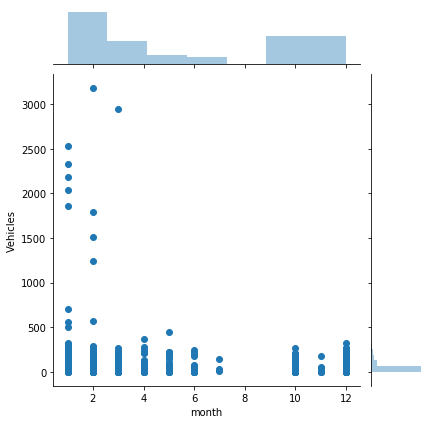

In [23]:
plt.figure(figsize=(10, 6))
sns.jointplot(x="month", y="Vehicles", data=df_transport)
# plt.title('Vehicles by Month')

#### データ品質の問題 #3:  
##### 特徴量列の名前変更と値の削除  

特徴量列の名前に大文字と小文字が混在しています。また、一部の列名には「スペース」が含まれています。さらに、関心があるのは 2006 年より大きい年のみであり、「<2006」ではありません。

名前を変更して特徴量列のすべてのスペースを削除しましょう。また、すべての特徴量列名を小文字にすることで「大文字・小文字」の問題も解決できます。

In [24]:
# TODO 3a
df_transport.rename(
    columns={
        "Date": "date",
        "Zip Code": "zipcode",
        "Model Year": "modelyear",
        "Fuel": "fuel",
        "Make": "make",
        "Light_Duty": "lightduty",
        "Vehicles": "vehicles",
    },
    inplace=True,
)
df_transport.head(2)

,date,zipcode,modelyear,fuel,make,lightduty,vehicles,year,month,day
0,2018-10-01,90000,2006,Gasoline,OTHER/UNK,Yes,1.0,2018,10,1
1,2018-10-01,90002,2014,Gasoline,OTHER/UNK,Yes,1.0,2018,10,1


 **注:** 次に、「SettingWithCopyWarning: A value is trying to be set on a copy of a slice from a DataFrame」という警告を回避するために、DataFrame のコピーを作成します。セルを実行して、modelyear 特徴量列から値 '<2006' を削除します。

In [25]:
# ここで、コピー警告の問題を回避するために DataFrame のコピーを作成します。

# TODO 3b

df = df_transport.loc[df_transport.modelyear != "<2006"].copy()

次に、値のカウント（value_counts）を実行して、modelyear の値 '<2006' が削除されたことを確認します。

In [26]:
df["modelyear"].value_counts(0)

2007    87
2012    81
2008    79
2011    77
2010    71
2006    70
2015    61
2014    59
2016    57
2017    57
2009    53
2013    52
2018    42
2019     6
Name: modelyear, dtype: int64

#### データ品質の問題 #4:  
##### カテゴリカル列の処理

特徴量列「lightduty」はカテゴリカルであり、「Yes/No」の選択肢があります。このような値をそのまま機械学習モデルに入力することはできません。Yes/No の文字列による二値回答を、1/0 の整数に変換する必要があります。これを実現するにはさまざまな方法があります。ここでは lambda 式を指定した `apply` メソッドを使用します。`pandas.Series.apply()` は関数を受け取り、Pandas Series のすべての値に適用します。

##### Lambda 関数とは？

通常、Python では `def` キーワードを使用して関数を定義する必要があります。しかし、lambda 関数は無名（名前を持たない）関数です。lambda 関数の最も一般的なユースケースは、シンプルな 1 行の関数を必要とするコードです（lambda は単一の式のみを持ちます）。

コースの専門講座を進めるにつれて、lambda 関数が使用されている多くの例を目にすることになります。今こそ lambda 関数に慣れておく良い機会です。

まず、'lightduty' 特徴量列の「Yes」と「No」の数をカウントしてみましょう。

In [27]:
df["lightduty"].value_counts(0)

Yes    771
No      80
--       1
Name: lightduty, dtype: int64

Yes を 1 に、No を 0 に変換しましょう。`pandas.Series.apply()` は関数を受け取り、Pandas Series（例: lightduty）のすべての値に関数を適用します。

In [28]:
df.loc[:, "lightduty"] = df["lightduty"].apply(lambda x: 0 if x == "No" else 1)
df["lightduty"].value_counts(0)

1    772
0     80
Name: lightduty, dtype: int64

In [29]:
# "lightduty" が変換されたことを確認します。

df.head()

,date,zipcode,modelyear,fuel,make,lightduty,vehicles,year,month,day
0,2018-10-01,90000,2006,Gasoline,OTHER/UNK,1,1.0,2018,10,1
1,2018-10-01,90002,2014,Gasoline,OTHER/UNK,1,1.0,2018,10,1
3,2018-10-01,90000,2017,Gasoline,OTHER/UNK,1,1.0,2018,10,1
16,2018-10-09,90001,2006,Diesel and Diesel Hybrid,Type_C,0,16.0,2018,10,9
17,2018-10-10,90001,2006,Diesel and Diesel Hybrid,OTHER/UNK,0,23.0,2018,10,10


#### カテゴリカル特徴量列のワンホット エンコーディング

機械学習アルゴリズムは、カテゴリカル特徴量ではなく入力ベクトルを想定しています。具体的には、テキストや文字列の値を直接処理することはできません。したがって、カテゴリカル特徴量をベクトルに変換することが多くの場合役立ちます。

変換方法の 1 つは、カテゴリカル特徴量のダミー変数を作成することです。ダミー変数とは、カテゴリカル特徴量の単一のクラスをそれぞれ表す一連のバイナリ（0 または 1）変数です。単純にカテゴリ変数をワンホット ベクトル（1 つの要素だけが非ゼロ（hot）であるベクトル）としてエンコードします。ワンホット エンコーディングを使用すると、カテゴリカル特徴量はその特徴量の選択肢の数をサイズとする配列になります。

Pandas は、カテゴリ変数をダミー / 指標変数に変換する `get_dummies` という関数を提供しています。

In [30]:
# より多くの入力値を持つカテゴリカル データのダミー変数を作成します。

data_dummy = pd.get_dummies(
    df[["zipcode", "modelyear", "fuel", "make"]], drop_first=True
)
data_dummy.head()

,zipcode_90001,zipcode_90002,zipcode_90003,zipcode_9001,zipcode_na,modelyear_2007,modelyear_2008,modelyear_2009,modelyear_2010,modelyear_2011,...,make_Type_Q,make_Type_R,make_Type_S,make_Type_T,make_Type_U,make_Type_V,make_Type_W,make_Type_X,make_Type_Y,make_Type_Z
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [31]:
# 元の DataFrame と「ダミー」DataFrame をマージ（連結）します。

# TODO 4a

df = pd.concat([df, data_dummy], axis=1)
df.head()

,date,zipcode,modelyear,fuel,make,lightduty,vehicles,year,month,day,...,make_Type_Q,make_Type_R,make_Type_S,make_Type_T,make_Type_U,make_Type_V,make_Type_W,make_Type_X,make_Type_Y,make_Type_Z
0,2018-10-01,90000,2006,Gasoline,OTHER/UNK,1,1.0,2018,10,1,...,0,0,0,0,0,0,0,0,0,0
1,2018-10-01,90002,2014,Gasoline,OTHER/UNK,1,1.0,2018,10,1,...,0,0,0,0,0,0,0,0,0,0
3,2018-10-01,90000,2017,Gasoline,OTHER/UNK,1,1.0,2018,10,1,...,0,0,0,0,0,0,0,0,0,0
16,2018-10-09,90001,2006,Diesel and Diesel Hybrid,Type_C,0,16.0,2018,10,9,...,0,0,0,0,0,0,0,0,0,0
17,2018-10-10,90001,2006,Diesel and Diesel Hybrid,OTHER/UNK,0,23.0,2018,10,10,...,0,0,0,0,0,0,0,0,0,0


In [32]:
# ダミー変数を作成した属性を削除します。Date 列も削除しましょう。

# TODO 4b

df = df.drop(["date", "zipcode", "modelyear", "fuel", "make"], axis=1)

In [33]:
# 'zipcode'、'modelyear'、'fuel'、'make' が削除されたことを確認します。

df.head()

,lightduty,vehicles,year,month,day,zipcode_90001,zipcode_90002,zipcode_90003,zipcode_9001,zipcode_na,...,make_Type_Q,make_Type_R,make_Type_S,make_Type_T,make_Type_U,make_Type_V,make_Type_W,make_Type_X,make_Type_Y,make_Type_Z
0,1,1.0,2018,10,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1.0,2018,10,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,1.0,2018,10,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16,0,16.0,2018,10,9,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17,0,23.0,2018,10,10,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### データ品質の問題 #5:  
##### 時間的特徴量列

データセットに year、month、day の特徴量列が含まれるようになりました。時間的特徴量は見落とされがちであるため、それらを変換することについて考えるきっかけとして、month 列と day 列を有意義な表現に変換してみましょう。

この専門講座の「特徴量エンジニアリング（Feature Engineering）」コースでは、year、month、day、hour の特徴量列を処理する方法についてより詳しく説明します。

まず、データセット内の「month」と「day」の一意の値を出力してみましょう。

In [34]:
print("Unique values of month:", df.month.unique())
print("Unique values of day:", df.day.unique())
print("Unique values of year:", df.year.unique())

Unique values of month: [10 11 12  1  2  3  4  5  6  7]
Unique values of day: [ 1  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31
  2  3  4  5  6  7  8]
Unique values of year: [2018 2019]


次に、各時間的変数を円上にマッピングし、その変数の最小値が最大値のすぐ隣に配置されるようにします。三角関数の sin と cos を使用して、その点の x 成分と y 成分を計算します。TensorFlow や Keras ではこれらの時間的特徴量列に対処する入力パイプラインを構築でき、その方がはるかに簡単なので、このコードを使用するのはこれが最後です。しかし、コースを進めるにつれて使わなくなる手法のありがたみを実感することも時には大切です。

セルを実行して出力を確認します。

In [ ]:
df["day_sin"] = np.sin(df.day * (2.0 * np.pi / 31))
df["day_cos"] = np.cos(df.day * (2.0 * np.pi / 31))
df["month_sin"] = np.sin((df.month - 1) * (2.0 * np.pi / 12))
df["month_cos"] = np.cos((df.month - 1) * (2.0 * np.pi / 12))

# month と day を削除します
# TODO 5
df = df.drop(["month", "day", "year"], axis=1)

In [39]:
# 変換された month 列と day 列を確認するには左（右）にスクロールしてください。
df.tail(4)

,lightduty,vehicles,zipcode_90001,zipcode_90002,zipcode_90003,zipcode_9001,zipcode_na,modelyear_2007,modelyear_2008,modelyear_2009,...,make_Type_U,make_Type_V,make_Type_W,make_Type_X,make_Type_Y,make_Type_Z,day_sin,day_cos,month_sin,month_cos
995,1,4.0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0.998717,-0.050649,0.5,-0.866025
996,1,25.0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0.968077,-0.250653,0.5,-0.866025
997,1,1.0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0.897805,-0.440394,0.5,-0.866025
998,1,3.0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0.790776,-0.612106,0.5,-0.866025


### 結論

このノートブックでは、データ品質を向上させるためのいくつかの概念を紹介しました。欠損値の解決、Date 特徴量列の datetime 形式への変換、特徴量列の名前変更、特徴量列からの値の削除、ワンホット エンコーディング特徴量の作成、時間的特徴量の有意義な表現への変換を行いました。このラボを通じて、機械学習モデルに入力する前にデータを「クリーンアップ」し「前処理」する必要がある理由を理解することができました。

Copyright 2020 Google Inc.
Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at
http://www.apache.org/licenses/LICENSE-2.0
Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License.